# WP13 FINAL DEMO v2 — Gerçek katkılardan deterministik Türkçe açıklama

Yeni attribution, forward, API veya eğitim yok. SHAP B1; tekil mesaj maskesi A1P1; biyolojik mekanizma NOT_ESTABLISHED.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP13/final_demo_v2';F=ROOT/'reports/figures/WP13/final_demo_v2'
display(pd.read_csv(Q/'full_native_PT_coverage.csv'));display(pd.read_json(Q/'complete_scan_summary.json',typ='series'));display(pd.read_csv(Q/'C0000731_C0000737_checks.csv'))

,model,context,protocol,drug_id,PT_count
0,B1_SHAP,primary_o01_final,primary,DB00254,220
1,B1_SHAP,primary_o01_final,primary,DB00438,220
2,B1_SHAP,primary_o01_final,primary,DB00446,220
3,B1_SHAP,primary_o01_final,primary,DB00479,220
4,B1_SHAP,primary_o01_final,primary,DB00493,220
...,...,...,...,...,...
225,A1P1,stress_o05_final,stress,DB00911,245
226,A1P1,stress_o05_final,stress,DB00916,245
227,A1P1,stress_o05_final,stress,DB00976,245
228,A1P1,stress_o05_final,stress,DB01044,245


graph    2440976
shap      167124
dtype: int64

,drug_id,PT,fold,SHAP_additivity_error,delta_identity_max_error,B1_sigmoid_proxy_error
0,DB00199,C0000731,3,7.448486e-12,7.800000e-08,1.559575e-11
1,DB00199,C0000737,3,3.401501e-11,8.000000e-08,3.481260e-11
2,DB00254,C0000731,1,3.634715e-11,1.456000e-07,4.277273e-12
3,DB00254,C0000737,1,2.066936e-11,1.012000e-07,1.617362e-11


**Yorum:** Tam mevcut tablolar tarandı; 2.608.100 katkı satırı yeni hesap değildir. Fold hedefleri birleştirilip doldurulmaz. Dört örnekte SHAP toplamı/logit ve Δz işareti kontrol edildi.

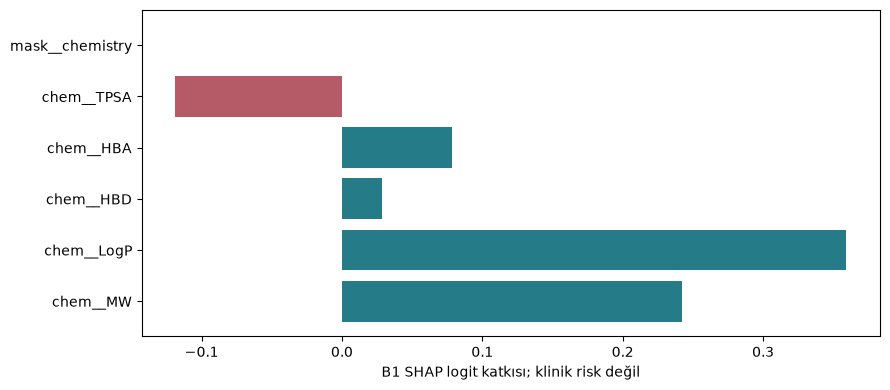

,feature,SHAP,Türkçe yorum
0,chem__MW,0.242398,B1 — Kimyasal özellik: Molekül ağırlığı. SHAP logit katkısı 0.242398250209756; eğitim background...
1,chem__LogP,0.359398,B1 — Kimyasal özellik: LogP. SHAP logit katkısı 0.3593980410771001; eğitim background'una göre m...
2,chem__HBD,0.028581,B1 — Kimyasal özellik: Hidrojen bağı verici sayısı. SHAP logit katkısı 0.0285811003012977; eğiti...
3,chem__HBA,0.078294,B1 — Kimyasal özellik: Hidrojen bağı alıcı sayısı. SHAP logit katkısı 0.0782944066226139; eğitim...
4,chem__TPSA,-0.118715,B1 — Kimyasal özellik: Topolojik polar yüzey alanı. SHAP logit katkısı -0.1187150860033192; eğit...
5,mask__chemistry,-0.000000,B1 — Eksiklik/modalite maskesi: mask__chemistry. SHAP logit katkısı -0.0; eğitim background'una ...


In [2]:
import wp13_explain_v2 as explain
a=explain.get('DB00199','C0000731',3)
s=pd.DataFrame(a['shap']);g=pd.DataFrame(a['graph']);fixed=g[g['mode'].eq('fixed')].copy()
fig,ax=plt.subplots(figsize=(9,4));ax.barh(s.feature,s.SHAP_logit,color=['#267b89' if v>=0 else '#b55a67' for v in s.SHAP_logit]);ax.set_xlabel('B1 SHAP logit katkısı; klinik risk değil');plt.tight_layout();plt.savefig(F/'03_real_B1_SHAP_signed.png',dpi=170);plt.show()
display(pd.DataFrame([{'feature':r['feature'],'SHAP':r['SHAP_logit'],'Türkçe yorum':explain.shap_sentence(r)} for r in a['shap']]))

**Yorum:** Pozitif B1 logitini artırıcı, negatif azaltıcı katkıdır; maske kimyasal özellik değildir. Bu A1P1 açıklaması değildir. Tam değerler CSV’de korunur; klinik yüzdeye dönüşüm yapılmaz.

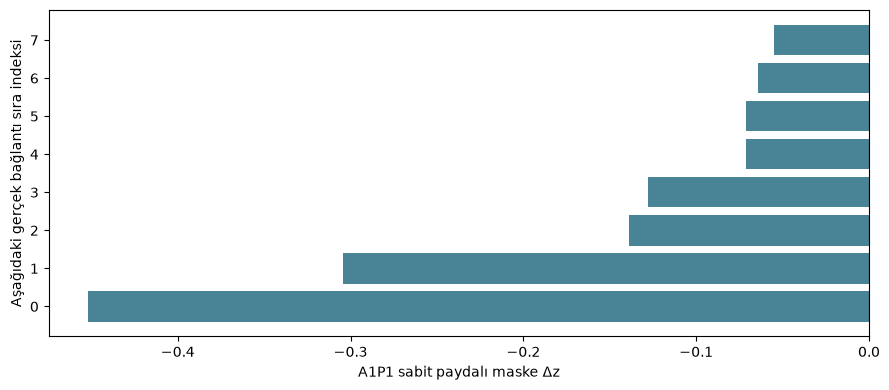

,kind,role,protein_id,protein_a,protein_b,delta_z
0,role,target,O43193,NaN,NaN,-0.452095
1,role,target,Q12809,NaN,NaN,-0.304226
2,role,transporter,Q9Y6L6,NaN,NaN,-0.139160
3,role,transporter,Q9NPD5,NaN,NaN,-0.128120
4,role,enzyme,P20815,NaN,NaN,-0.071364
5,role,transporter,P46721,NaN,NaN,-0.071286
6,role,enzyme,P08684,NaN,NaN,-0.064220
7,role,enzyme,P24462,NaN,NaN,-0.054832


,yorum
0,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.4520949; müdahaleden sonr...
1,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.30422556; müdahaleden son...
2,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.1391604; müdahaleden sonr...
3,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.12811959; müdahaleden son...
4,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.071363926; müdahaleden so...
5,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.07128608; müdahaleden son...
6,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.06422043; müdahaleden son...
7,A1P1 — Sabit derece/rol paydalı mesaj maskesi. Δz=orijinal−müdahale=-0.054831505; müdahaleden so...


In [3]:
plot=fixed.assign(abs_effect=fixed.delta_z.abs()).sort_values('abs_effect',ascending=False).head(8).reset_index(drop=True)
fig,ax=plt.subplots(figsize=(9,4));ax.barh(plot.index.astype(str),plot.delta_z,color='#498396');ax.set(xlabel='A1P1 sabit paydalı maske Δz',ylabel='Aşağıdaki gerçek bağlantı sıra indeksi');plt.tight_layout();plt.savefig(F/'04_real_A1P1_signed_delta.png',dpi=170);plt.show()
display(plot[['kind','role','protein_id','protein_a','protein_b','delta_z']]);display(pd.DataFrame({'yorum':[explain.delta_sentence(r) for r in plot.to_dict('records')]}))

**Yorum:** Görsel en büyük mutlak8 müdahaleyi gösterir; seçim modeli/deneyi değiştirmez. Δz pozitifse müdahale logiti azaltmış, negatifse artırmıştır. Deletion/renormalization ayrı yöntemdir. Tekil etkiler toplamsal biyolojik nedenler değildir.

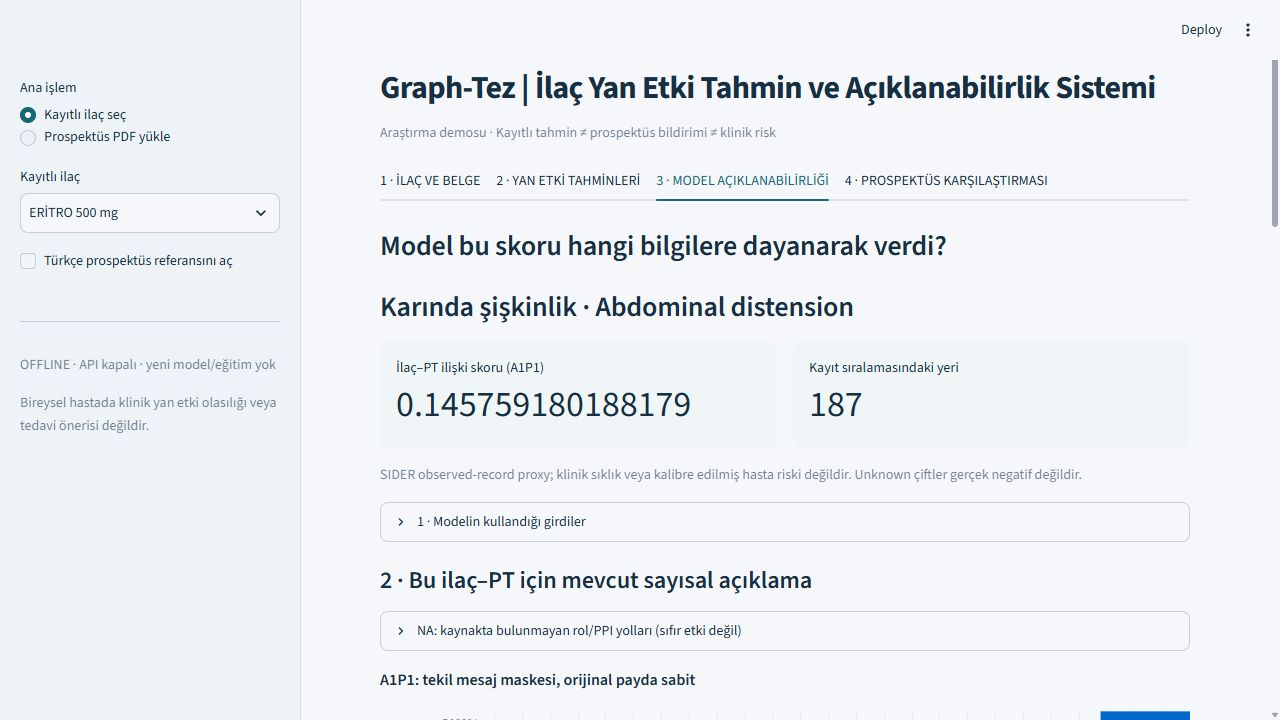

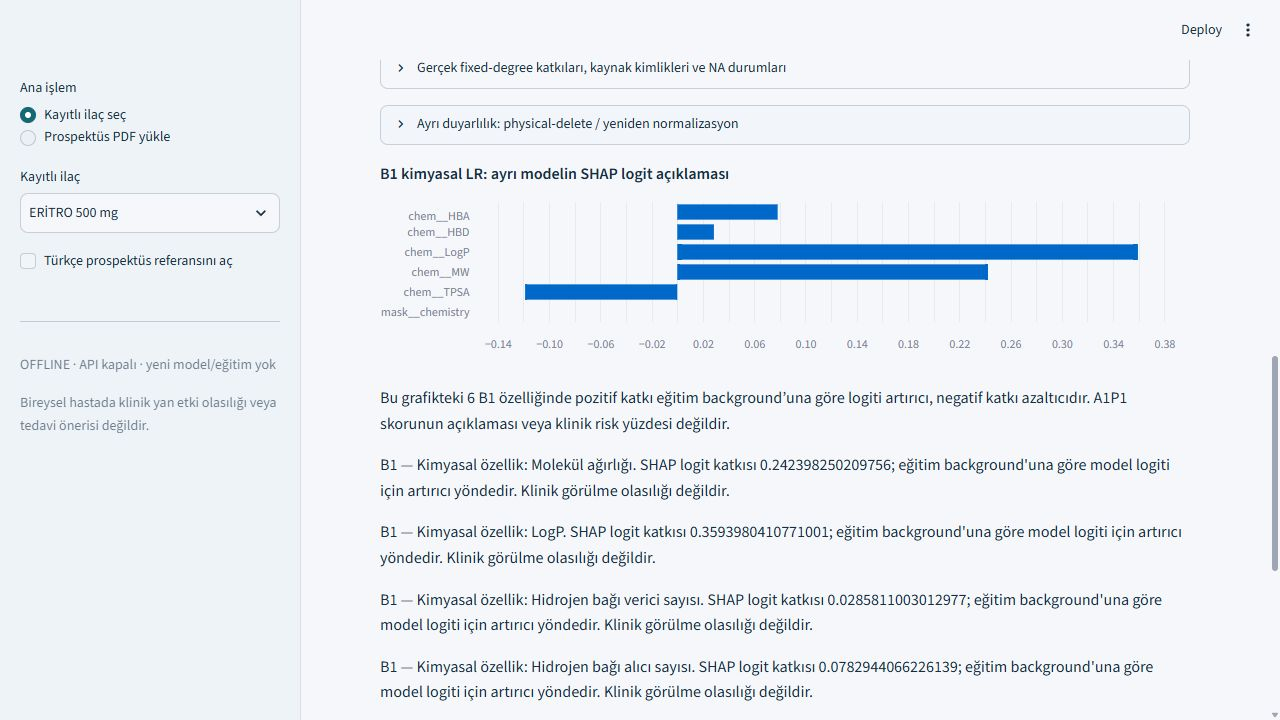

In [4]:
from IPython.display import Image
for f in ['02_final_A1P1_verbal.jpg','05_final_B1_verbal.jpg']:display(Image(filename=str(F/f),width=1000))

**Yorum:** Gerçek localhost8510 ekranlarıdır. Tahmin/PDF kolları ayrı; uzman PT eşlemesi yoksa UNMAPPED/PENDING. Dış adapter yalnız sözleşme/plan; gerçek dış ilaç tahmini NOT_RUN.